# Comparative chronological age analysis — Horvath clock

This notebook addresses a key artefact in the broader comparative analysis: **linear clocks are by design "perfect" at zero missingness** because missingness metrics are scored against the clock's own baseline prediction (MAE = 0, r = 1, R² = 1 at frac = 0). This masks the fact that for Horvath — a clock explicitly designed to predict **chronological age** — the more meaningful ground truth is chronological age itself.

By re-scoring all models against chronological age, we place EpiHydra and the Horvath linear clock on a **common, biologically meaningful reference scale** and can honestly ask: which model better predicts actual age when probes go missing?

| Comparison axis | What it measures |
|---|---|
| Masked prediction vs. own baseline | Stability / degradation from missingness (previous notebooks) |
| **Masked prediction vs. chronological age** | **Absolute biological accuracy under missingness (this notebook)** |

**Models compared** at removal fractions 10%, 25%, 50%, 75%:
- **EpiHydra** — transformer clock, missing CpGs stay masked
- **EpiHydra (imputed)** — same backbone, missing CpGs replaced by per-token reference mean
- **Horvath (linear)** — published Horvath 2013 elastic-net clock

Figures are production-ready at **Nature Medicine** specifications (300 dpi, Arial, single/double column 89/183 mm).

## 0 · Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path
import numpy as np

# ── The single clock under study ──────────────────────────────────────────────
CLOCK = 'horvath_age'

# ── Removal fractions to analyse (the four key levels) ───────────────────────
REMOVAL_FRACTIONS = [0.10, 0.25, 0.50, 0.75]
# Also include baseline (0.0) so scatter panels can show the unmasked state
ALL_FRACTIONS     = [0.0] + REMOVAL_FRACTIONS

# ── Paths ─────────────────────────────────────────────────────────────────────
ROOT     = Path('/work/gr-fe/bryan/EpiHydra')
RESULTS  = ROOT / 'results'


EPIHYDRA_PRED_DIR  = RESULTS / 'per_sample_preds/epihydra'
LINEAR_SYST_CSV = RESULTS / 'linear_clocks/missingness/per_cpg/horvath_persample_systematic.csv'

# ── Output ────────────────────────────────────────────────────────────────────
SAVE_DIR = Path('figures/ComparativeChronAgeModel')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print('Clock          :', CLOCK)
print('Fractions      :', REMOVAL_FRACTIONS)
print('Figures to     :', SAVE_DIR.resolve())

Clock          : horvath_age
Fractions      : [0.1, 0.25, 0.5, 0.75]
Figures to     : /work/gr-fe/bryan/EpiHydra/notebooks/05_results/figures/ComparativeChronAgeModel


## 1 · Imports

In [2]:
import json
import pickle
import warnings

warnings.filterwarnings('ignore', message='.*IProgress.*')
warnings.filterwarnings('ignore', message='.*flash_attn.*')
warnings.filterwarnings('ignore', message='.*nested tensor.*')

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
from matplotlib.lines  import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import torch

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from evaluation import eval_utils as eu
from evaluation.eval_utils import (
    _NM_RC,
    _MM,
    _clean,
    _METRIC_LABEL,
    _HIGH_IS_GOOD,
    _scatter_panel,
    compute_metrics,
)
from epihydra import VocabWrapper, build_multiclock_dataloaders
from clocks.epigenetic_clocks import (
    Horvath,
    build_cpg_reference,
    run_all_clocks,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 2 · Model & data configuration

Paths are identical to notebook 04 (EpiHydra) and 05 (linear) so the same held-out test set is used throughout.

In [3]:
# ── EpiHydra paths ────────────────────────────────────────────────────────────
DATA_PATH     = ROOT / 'data/03_final/combined_test/methylation.pkl'
MODEL_PATH    = ROOT / 'data/03_final/methylgpt/medium'
EPIHYDRA_PATH = ROOT / 'results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739'
HEAD_PATH     = ROOT / 'results/tensorboard/ckpt/clocks3_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261115_120827'
LORA_CKPT     = EPIHYDRA_PATH / 'best_model.pt'
NUM_HEADS     = 4

# ── Linear clock paths ────────────────────────────────────────────────────────
DATASET_IDS           = ['GSE84727', 'GSE179325']
DATA_ROOT             = ROOT / 'data/02_processed'
COEF_ROOT             = ROOT / 'data/03_final'
HORVATH_CSV           = COEF_ROOT / 'Horvath/horvath.csv'
REFERENCE_DATASET_IDS = [
    'GSE40279', 'GSE55763', 'GSE111629', 'GSE157131',
    'GSE42861', 'GSE169156', 'GSE210255',
]

SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
BATCH_SIZE   = 32
MASK_SEED    = 42

## 3 · Load EpiHydra model and data

In [4]:
import json

print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

clocks_to_run = eu.resolve_clocks(None, HEAD_PATH)   # ['age', 'hannum_age', 'horvath_age', ...]
print('All available clocks:', clocks_to_run)

# We only need age (chron) + horvath_age for this notebook
clocks_to_run = [c for c in clocks_to_run if c in ('age', CLOCK)]
print('Running clocks      :', clocks_to_run)

dataloader = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clocks_to_run,
    batch_size   = BATCH_SIZE,
    random_state = MASK_SEED,
    **SPLIT_RATIOS,
)
loader  = eu.ordered_loader(dataloader['loader'])
scalers = eu.load_scalers(HEAD_PATH, epihydra_path=EPIHYDRA_PATH)

print(f"Test samples: {len(loader.dataset):,}")

Loading data...
All available clocks: ['age', 'hannum_age', 'horvath_age', 'phenoage_age']
Running clocks      : ['age', 'horvath_age']
Samples in meta : 1239
Samples in CpG  : 1239
Common samples  : 1239
Samples after drop : 1239
  age                 : 1239 labeled
  horvath_age         : 1239 labeled

Vocab CpGs : 49,159 | Present : 45,069 (91.7%) | Missing : 4,090
ℹ  age                 : scaler fitted on all values (no-split mode).
ℹ  horvath_age         : scaler fitted on all values (no-split mode).
✓ Single multi-clock loader built (1239 samples, no masking).

Test samples: 1,239


/work/gr-fe/bryan/EpiHydra/epihydra/epihydra.py:125: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(X, axis=0)                  # (n_cpgs,) — NaN where all-NaN probe


In [5]:
mc_model = eu.build_multiclock_model(
    MODEL_PATH, vocab, pretrain_config, device,
    ckpt       = LORA_CKPT,
    head_path  = HEAD_PATH,
    clock_names = clocks_to_run,
    num_heads  = NUM_HEADS,
)

# Per-CpG imputation reference (for the imputed variant)
ref_df_parts = {}
for gse in REFERENCE_DATASET_IDS:
    with open(DATA_ROOT / gse / 'methylation.pkl', 'rb') as f:
        ref_df_parts[gse] = pickle.load(f)['CpG']

ref_df_parts = {
    gse: df.loc[df.index.intersection(vocab.CpG_list)]
    for gse, df in ref_df_parts.items()
}

reference_series = build_cpg_reference(ref_df_parts)
impute_ref = eu.reference_by_token(reference_series, vocab, device)

I0000 00:00:1794838475.249676 3181823 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794838480.953026 3181823 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794838502.360279 3181823 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


LoRA from checkpoint: r=16, alpha=32


/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739/best_model.pt
  source run   : nlayers6_nhead4_emb256_lora16a32_lr3e-04_heads4_20261113_171739
  source epoch : 28  (valid MAE 3.119)
  lora_r=16 lora_alpha=32 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt
  loaded head horvath_age          <- best_head_horvath_age.pt (epoch 47)
Reference values for 49,156 of 49,159 vocab CpGs


## 4 · Load linear Horvath model and data

In [6]:
import gc
import sys
sys.path.insert(0, '../02_epiclocks/')
from clocks.epigenetic_clocks import (
    Horvath, build_cpg_reference, run_all_clocks,
)

horvath = Horvath(HORVATH_CSV)
clocks  = {CLOCK: horvath}

NON_PROBE_LABELS = {'Intercept', 'Age', 'Female', 'Male', '__hannum_intercept__'}
cpg_col    = getattr(horvath, 'CPG_COL', 'CpG')
clock_probes = {
    CLOCK: set(
        p for p in horvath.coefficients[cpg_col]
        if p not in NON_PROBE_LABELS
    )
}
print(f'Horvath CpG probes: {len(clock_probes[CLOCK]):,}')

# Load held-out beta matrices and chronological ages
dataset    = {}
chron_ages = {}
for gse in DATASET_IDS:
    with open(DATA_ROOT / gse / 'methylation.pkl', 'rb') as f:
        pkl = pickle.load(f)
    dataset[gse]    = pkl['CpG']
    chron_ages[gse] = pkl['meta'].set_index('ID')['age']

# Per-CpG reference for linear imputation
ref_parts_lin = {}
for gse in REFERENCE_DATASET_IDS:
    with open(DATA_ROOT / gse / 'methylation.pkl', 'rb') as f:
        cpg = pickle.load(f)['CpG']
        ref_parts_lin[gse] = cpg.loc[cpg.index.intersection(list(clock_probes[CLOCK]))]
        del cpg
    gc.collect()

reference_lin = build_cpg_reference(ref_parts_lin)
IMPUTE_KW     = dict(
    impute_missing=True,
    impute_within_cohort=True,
    impute_reference=reference_lin,
)
print('Linear reference built.')

Loaded 353 CpG coefficients + intercept.
Horvath CpG probes: 354
Linear reference built.


## 5 · Run inference at each removal fraction

For every removal fraction we produce three per-sample prediction DataFrames, each with columns:
- `pred` — predicted Horvath age
- `chron_age` — chronological age (ground truth for all models)
- `frac` — removal fraction
- `model` — model identifier

In [7]:
# ── Helper: rank Horvath probes for linear systematic removal ─────────────────

def rank_cpgs_linear_horvath(dataset, probes, strategy='high_variance'):
    """Rank Horvath CpG probes by variance (descending) for systematic removal."""
    observed_probes = set()
    for cpg_df in dataset.values():
        observed_probes.update(cpg_df.index[cpg_df.notna().any(axis=1)].tolist())

    eligible = sorted(probes & observed_probes)
    probe_vals = {p: [] for p in eligible}
    for cpg_df in dataset.values():
        present = [p for p in eligible if p in cpg_df.index]
        for probe in present:
            probe_vals[probe].extend(cpg_df.loc[probe].dropna().values.astype(float).tolist())

    scores = {p: float(np.var(np.array(v)[np.isfinite(np.array(v))])) if v else np.nan
              for p, v in probe_vals.items()}
    s = pd.Series(scores).dropna()
    ascending = strategy == 'low_variance'
    ranked_probes = s.sort_values(ascending=ascending).index.tolist()
    unobserved = [p for p in eligible if p not in s.index]
    return ranked_probes + unobserved


# ── Helper: run Horvath linear on a masked dataset ────────────────────────────

def _run_horvath(masked_dataset):
    """Run Horvath on a {gse: beta_df} dict. Returns Series(id -> pred)."""
    raw = run_all_clocks(
        datasets     = masked_dataset,
        save_path    = '',
        clocks       = clocks,
        chron_ages   = chron_ages,
        save_summary = False,
        verbose      = False,
        **IMPUTE_KW,
    )
    parts = [age_df[CLOCK].dropna() for age_df in raw.values()]
    return pd.concat(parts)


# Pool chronological ages across datasets aligned to sample IDs
all_chron = pd.concat([chron_ages[gse] for gse in DATASET_IDS])

# RNG for per-sample linear masking — same seed as EpiHydra (MASK_SEED)
# so both models hide equivalent fractions under the same random draw.
rng = np.random.default_rng(MASK_SEED)

print('Setup complete — ready to run inference.')

Setup complete — ready to run inference.


In [8]:
# ── Per-sample random masking for the linear clock ───────────────────────────
# Mirrors _apply_masking() in eval_utils: for each sample independently,
# draw a random fraction of that sample's observed (non-NaN) probes and set
# them to NaN. The rng is re-seeded at each fraction so draws are independent
# across fractions but deterministic for reproducibility.

def mask_random_cpgs_per_sample(dataset, probes, mask_frac, seed):
    """
    Per-sample independent random masking for the linear Horvath clock.

    For every sample column, a fresh random draw selects mask_frac of that
    sample's own observed probes and sets them to NaN.  This matches
    _apply_masking(frac=mask_frac) in eval_utils which calls torch.randperm
    independently for each sample in the batch.

    Parameters
    ----------
    dataset   : {gse: beta_df}  (CpGs × samples)
    probes    : set of Horvath CpG probe IDs
    mask_frac : fraction of each sample's observed probes to hide
    seed      : integer seed so the same draws are used across EpiHydra
                and linear runs at the same fraction

    Returns
    -------
    masked : {gse: masked_beta_df}
    """
    rng_local = np.random.default_rng(seed)
    masked = {}
    for gse, cpg_df in dataset.items():
        clock_rows = cpg_df.index.intersection(probes)
        df = cpg_df.loc[clock_rows].copy()
        if mask_frac > 0.0:
            for sample_id in df.columns:
                col      = df[sample_id]
                eligible = col.index[col.notna()].tolist()
                if not eligible:
                    continue
                n_remove  = max(1, int(len(eligible) * mask_frac))
                to_remove = rng_local.choice(eligible, size=n_remove, replace=False)
                df.loc[to_remove, sample_id] = np.nan
        masked[gse] = df.dropna(how='all')
    return masked


# ── Main inference loop ───────────────────────────────────────────────────────
# EpiHydra : mask_frac=frac passed to predict_multiclock, which calls
#            _apply_masking(frac=frac) independently per sample in the batch.
# Linear   : mask_random_cpgs_per_sample applies the same logic on the
#            beta-value DataFrame before running the linear clock.
# Both use MASK_SEED so they operate under equivalent stochastic conditions.

sample_records = []

for frac in ALL_FRACTIONS:

    # ── 1. EpiHydra (raw) ────────────────────────────────────────────────────
    # mask_frac triggers the per-sample random path in _apply_masking().
    # seed=MASK_SEED pins the torch.randperm draws for reproducibility.
    preds_raw = eu.predict_multiclock(
        mc_model, loader, scalers, device,
        clock_names = clocks_to_run,
        mask_frac   = frac,
        seed        = MASK_SEED,
    )
    df_raw = preds_raw[[f'{CLOCK}_pred', f'{CLOCK}_true', 'age_true']].copy()
    df_raw.columns = ['pred', 'horvath_true', 'chron_age']
    df_raw['frac']  = frac
    df_raw['model'] = 'EpiHydra'
    sample_records.append(df_raw)

    # ── 2. EpiHydra (imputed) ────────────────────────────────────────────────
    # Same mask_frac + seed as above so the same CpGs are hidden;
    # impute_ref then fills them with per-token reference betas.
    preds_imp = eu.predict_multiclock(
        mc_model, loader, scalers, device,
        clock_names = clocks_to_run,
        mask_frac   = frac,
        seed        = MASK_SEED,
        impute_ref  = impute_ref,
    )
    df_imp = preds_imp[[f'{CLOCK}_pred', f'{CLOCK}_true', 'age_true']].copy()
    df_imp.columns = ['pred', 'horvath_true', 'chron_age']
    df_imp['frac']  = frac
    df_imp['model'] = 'EpiHydra (imputed)'
    sample_records.append(df_imp)

    # ── 3. Horvath linear ────────────────────────────────────────────────────
    # Per-sample masking with the same seed so each sample loses the same
    # fraction of its own observed probes as in EpiHydra.
    masked_lin = mask_random_cpgs_per_sample(
        dataset, clock_probes[CLOCK], mask_frac=frac, seed=MASK_SEED
    )
    preds_lin     = _run_horvath(masked_lin)
    chron_aligned = all_chron.reindex(preds_lin.index)
    df_lin = pd.DataFrame({
        'pred':         preds_lin.values,
        'horvath_true': preds_lin.values,   # linear clock IS the Horvath label
        'chron_age':    chron_aligned.values,
        'frac':         frac,
        'model':        'Horvath (linear)',
    }, index=preds_lin.index)
    sample_records.append(df_lin)

    print(f'frac={frac:.2f} done  '
          f'(EpiHydra n={len(df_raw)}, Linear n={len(df_lin)})')

# ── Combine ───────────────────────────────────────────────────────────────────
all_preds = pd.concat(sample_records, ignore_index=False)
all_preds.to_csv(SAVE_DIR / 'per_sample_predictions.csv')
print(f'\nSaved per-sample predictions → {SAVE_DIR / "per_sample_predictions.csv"}')
all_preds.head()

frac=0.00 done  (EpiHydra n=1239, Linear n=1239)
frac=0.10 done  (EpiHydra n=1239, Linear n=1239)
frac=0.25 done  (EpiHydra n=1239, Linear n=1239)
frac=0.50 done  (EpiHydra n=1239, Linear n=1239)
frac=0.75 done  (EpiHydra n=1239, Linear n=1239)

Saved per-sample predictions → figures/ComparativeChronAgeModel/per_sample_predictions.csv


,pred,horvath_true,chron_age,frac,model
GSM2250273,53.278374,57.724472,47.299999,0.0,EpiHydra
GSM2250274,63.447544,62.917908,60.400002,0.0,EpiHydra
GSM2250275,40.081905,38.569855,30.100000,0.0,EpiHydra
GSM2250276,50.251076,55.671482,47.700001,0.0,EpiHydra
GSM2250277,49.888653,50.631992,46.900002,0.0,EpiHydra


## 6 · Style palette

In [14]:
all_preds = all_preds[all_preds['model'] != 'EpiHydra (imputed)']

In [27]:
# Okabe–Ito colour-blind safe palette (Nature Medicine recommended)
MODEL_STYLE = {
    'EpiHydra':           {'color': '#0072B2', 'ls': '-',  'marker': 'o',  'lw': 1.2, 'zorder': 4},
    #'EpiHydra (imputed)': {'color': '#56B4E9', 'ls': '--', 'marker': 's',  'lw': 1.0, 'zorder': 3},
    'Horvath (linear)':   {'color': '#D55E00', 'ls': ':',  'marker': '^',  'lw': 1.0, 'zorder': 2},
}
MODEL_ORDER = ['EpiHydra', 'Horvath (linear)']

# Scatter colour by fraction — deeper blue = more missingness
FRAC_CMAP = plt.cm.Blues
FRAC_NORM = plt.Normalize(vmin=0.0, vmax=0.9)

# Panel letters A–Z for multi-panel figures
_PANEL_LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'


def _legend_handles(models=MODEL_ORDER):
    return [
        Line2D([0], [0],
               color=MODEL_STYLE[m]['color'],
               ls=MODEL_STYLE[m]['ls'],
               lw=MODEL_STYLE[m]['lw'],
               marker=MODEL_STYLE[m]['marker'],
               markersize=4,
               label=m)
        for m in models
    ]

print('Style palette registered.')

Style palette registered.


## 7 · Metric curves vs. chronological age

Unlike the previous notebooks (which scored masked predictions against baseline predictions), here every model is scored against **chronological age**. This is the honest comparison: Horvath's perfect score at frac=0 disappears because its MAE vs. chron age is ~6 years, the same absolute starting point as EpiHydra.

In [28]:
# ── Compute per-model, per-fraction metrics vs. chronological age ─────────────

metric_rows = []
for model in MODEL_ORDER:
    for frac in ALL_FRACTIONS:
        sub = all_preds[(all_preds['model'] == model) & (all_preds['frac'] == frac)].dropna(
            subset=['pred', 'chron_age']
        )
        m = compute_metrics(sub['chron_age'].values, sub['pred'].values)
        metric_rows.append({'model': model, 'frac': frac, **m})

metrics_df = pd.DataFrame(metric_rows).dropna()
metrics_df.to_csv(SAVE_DIR / 'metrics_vs_chron_age.csv', index=False)
print('Metrics vs. chronological age:')
display(
    metrics_df.pivot_table(index='frac', columns='model', values='mae')
    .round(2)
    .rename_axis('Removal fraction')
    .rename_axis('MAE vs. chron age (years)', axis=1)
)

Metrics vs. chronological age:


MAE vs. chron age (years),EpiHydra,Horvath (linear)
Removal fraction,,
0.00,5.57,6.33
0.10,6.00,6.67
0.25,6.34,7.30
0.50,6.97,8.84
0.75,9.81,10.59


Saved → figures/ComparativeChronAgeModel/metric_curve_mae.svg
Saved → figures/ComparativeChronAgeModel/metric_curve_mae.pdf


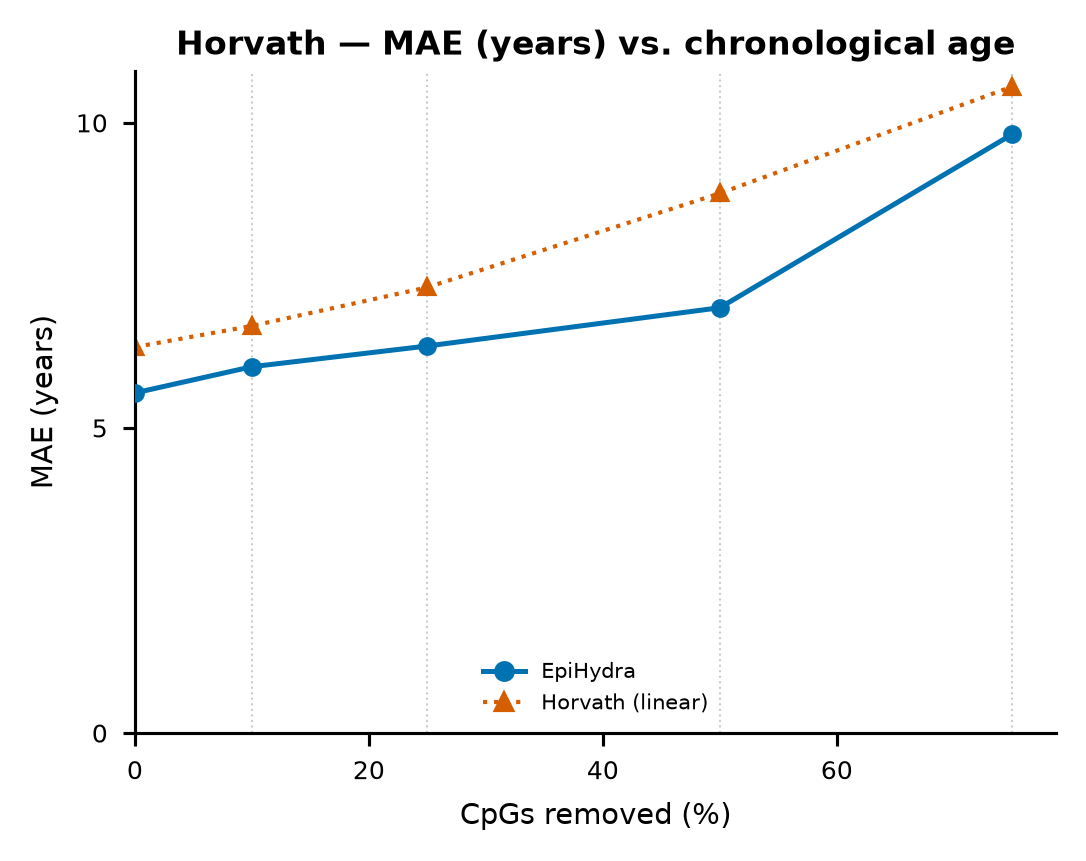

Saved → figures/ComparativeChronAgeModel/metric_curve_pearson_r.svg
Saved → figures/ComparativeChronAgeModel/metric_curve_pearson_r.pdf


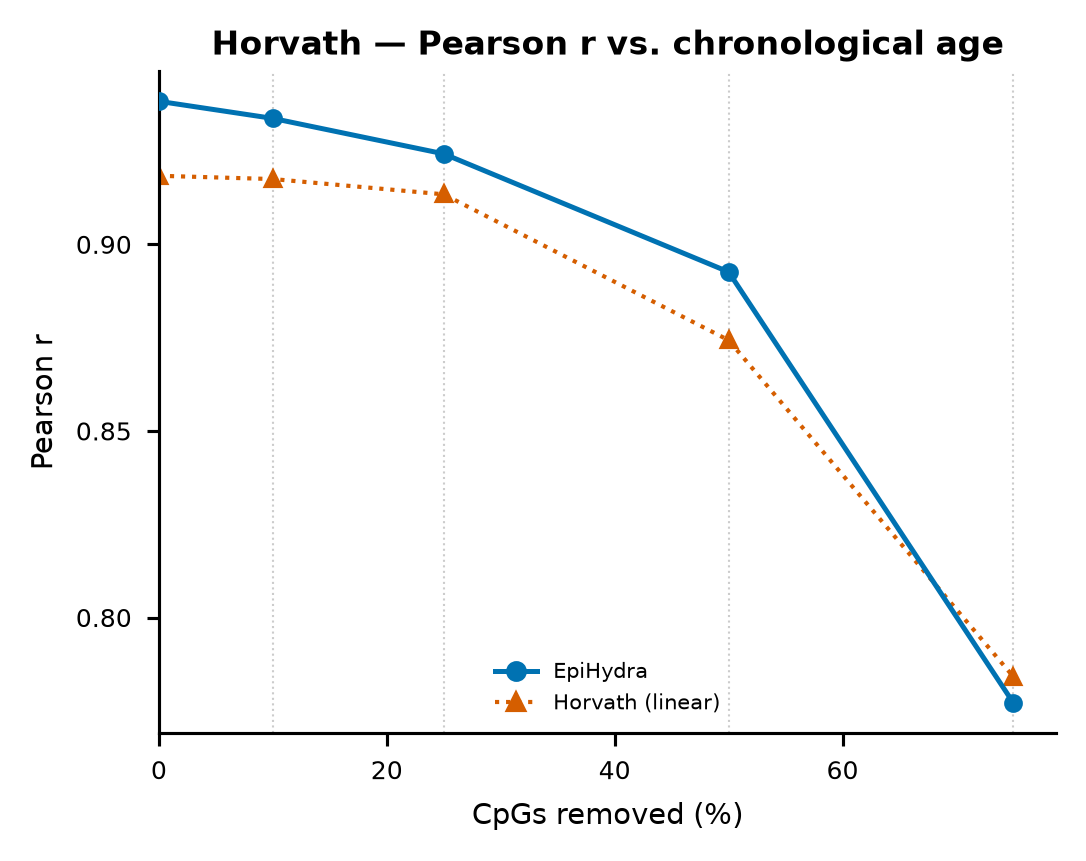

Saved → figures/ComparativeChronAgeModel/metric_curve_r2.svg
Saved → figures/ComparativeChronAgeModel/metric_curve_r2.pdf


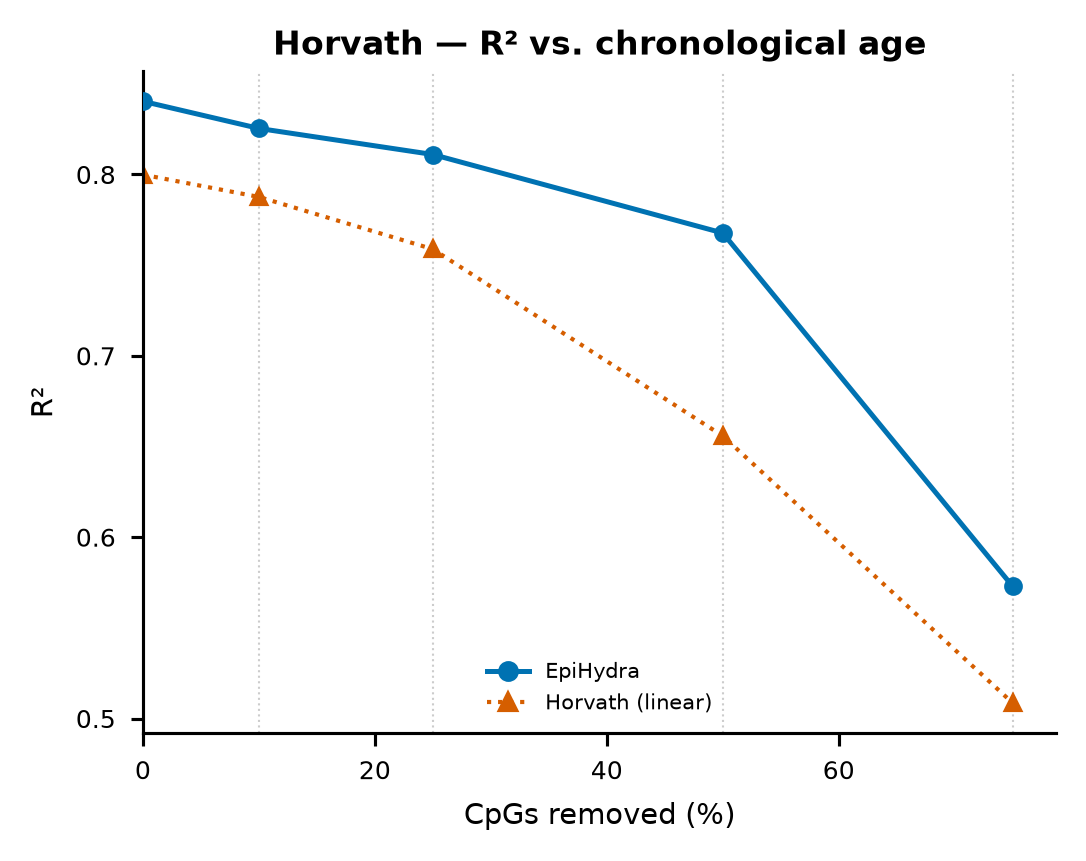

In [39]:
def _save_fig(fig, stem):
    for fmt in ('svg', 'pdf'):
        p = SAVE_DIR / f'{stem}.{fmt}'
        fig.savefig(p)
        print(f'Saved → {p}')


def plot_metric_curves(metrics_df, metric='mae', save_stem=None):
    """
    One panel: all three models, x = removal fraction, y = metric vs. chron age.
    Single NM column (89 mm).
    """
    with plt.rc_context(_NM_RC):
        fig, ax = plt.subplots(figsize=(89 * _MM, 70 * _MM), constrained_layout=True)

        for model in MODEL_ORDER:
            sub = metrics_df[metrics_df['model'] == model].sort_values('frac')
            # Restrict to the requested fractions (exclude frac=0 from x-axis
            # but include it as the leftmost data point to anchor the curve)
            s = MODEL_STYLE[model]
            ax.plot(
                sub['frac'] * 100, sub[metric],
                color=s['color'], ls=s['ls'],
                lw=s['lw'], marker=s['marker'],
                markersize=3.5, zorder=s['zorder'],
            )

        # Mark the four key fractions with vertical guides
        for frac in REMOVAL_FRACTIONS:
            ax.axvline(frac * 100, color='#CCCCCC', lw=0.5, ls=':', zorder=0)

        ax.set_xlabel('CpGs removed (%)')
        ax.set_ylabel(_METRIC_LABEL[metric])
        ax.set_title(
            f'Horvath — {_METRIC_LABEL[metric]} vs. chronological age',
            pad=4, fontweight='bold',
        )
        ax.set_xlim(left=0)
        if not _HIGH_IS_GOOD[metric]:
            ax.set_ylim(bottom=0)
        ax.legend(handles=_legend_handles(), frameon=False, fontsize=5, loc='best')

    if save_stem:
        _save_fig(fig, save_stem)
    return fig, ax


for metric in ('mae', 'pearson_r', 'r2'):
    fig, ax = plot_metric_curves(
        metrics_df, metric=metric,
        save_stem=f'metric_curve_{metric}',
    )
    plt.show()

## 8 · Scatter panels: predicted vs. chronological age at each fraction

**Figure layout:** rows = models (EpiHydra, EpiHydra imputed, Horvath linear), columns = removal fractions (0%, 10%, 25%, 50%, 75%). Each panel plots predicted Horvath age on the y-axis against chronological age on the x-axis. The identity line (*y* = *x*) shows perfect prediction.

> **Key insight:** At frac = 0 the linear Horvath clock has MAE ≈ 6 years vs. chronological age — not 0 — because it was trained to predict a re-calibrated "epigenetic age" that correlates with but is not identical to chronological age. EpiHydra targets the same label and starts at a similar absolute error. The question this figure answers is how that error evolves as probes disappear.

Saved → figures/ComparativeChronAgeModel/scatter_grid_vs_chron.svg
Saved → figures/ComparativeChronAgeModel/scatter_grid_vs_chron.pdf


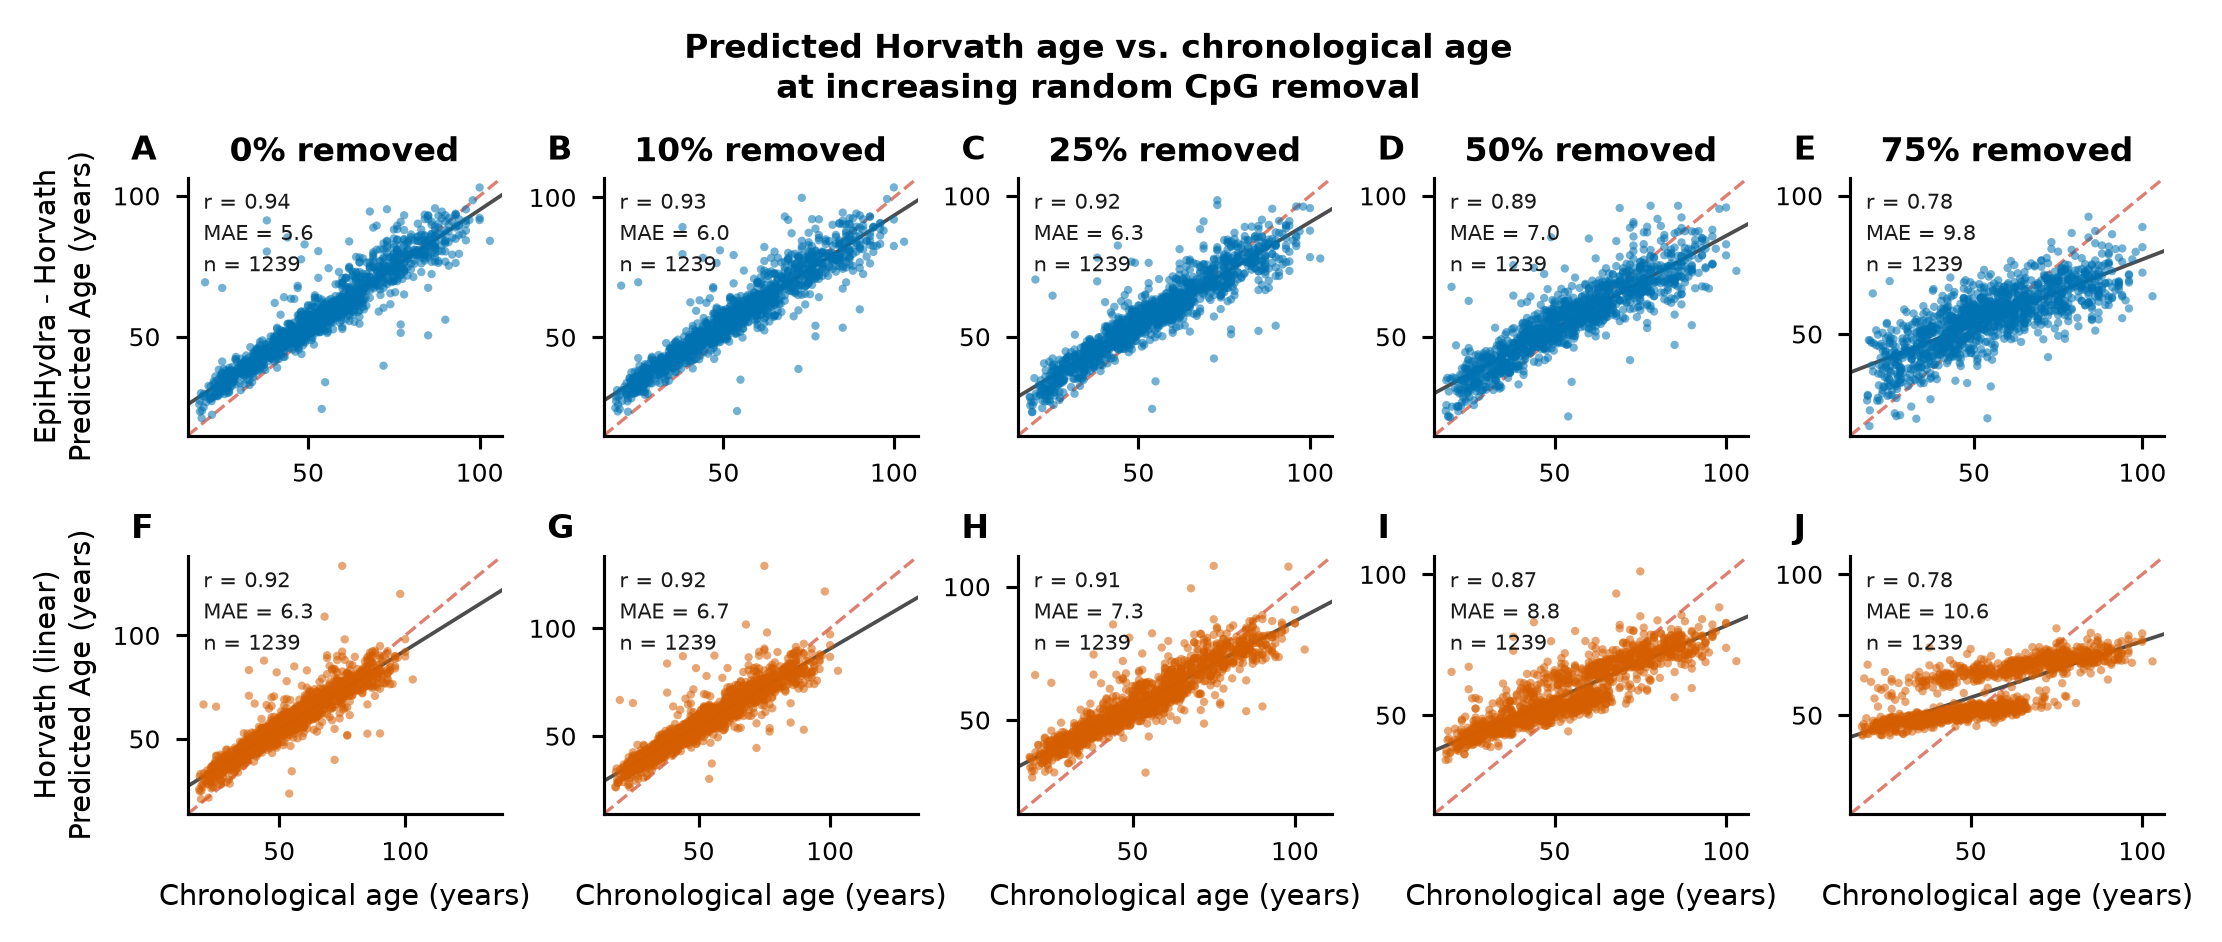

In [45]:
SCATTER_FRACS  = [0.0] + REMOVAL_FRACTIONS   # 5 columns
N_COLS         = len(SCATTER_FRACS)
N_ROWS         = len(MODEL_ORDER)

# Panel size: NM double column (183 mm) ÷ 5 columns
panel_w = (183 / N_COLS) * _MM
panel_h = panel_w * 1.05   # slightly taller to accommodate annotations


def _scatter_panel_chron(ax, pred, chron, frac, model, panel_letter):
    """
    One panel: predicted vs. chronological age.
    Uses _scatter_panel from eval_utils for consistent NM styling.
    """
    s = MODEL_STYLE[model]

    pred_arr  = np.asarray(pred,  dtype=float)
    chron_arr = np.asarray(chron, dtype=float)
    ok        = np.isfinite(pred_arr) & np.isfinite(chron_arr)
    pred_arr, chron_arr = pred_arr[ok], chron_arr[ok]

    stats = compute_metrics(chron_arr, pred_arr)

    # Scatter
    ax.scatter(
        chron_arr, pred_arr,
        s=4, facecolor=s['color'], edgecolor='none',
        alpha=0.55, zorder=3, rasterized=True,
    )

    lo = min(chron_arr.min(), pred_arr.min())
    hi = max(chron_arr.max(), pred_arr.max())
    pad = (hi - lo) * 0.04
    lims = np.array([lo - pad, hi + pad])

    # Identity line y = x
    ax.plot(lims, lims, color='#D6604D', lw=0.8, ls='--', alpha=0.8, zorder=2)
    # Regression line
    if stats['n'] >= 2 and np.std(chron_arr) > 0:
        m_reg, b_reg = np.polyfit(chron_arr, pred_arr, 1)
        ax.plot(lims, m_reg * lims + b_reg, color='#4D4D4D', lw=0.9, zorder=2)

    ax.set_xlim(lims)
    ax.set_ylim(lims)

    # Stats annotation
    ax.text(
        0.05, 0.97,
        f'r = {stats["pearson_r"]:.2f}\n'
        f'MAE = {stats["mae"]:.1f}\n'
        f'n = {stats["n"]}',
        transform=ax.transAxes,
        fontsize=5, va='top', linespacing=1.5, color='#1a1a1a',
    )

    # Panel letter top-left
    ax.text(
        -0.18, 1.04, panel_letter,
        transform=ax.transAxes,
        fontsize=8, fontweight='bold', va='bottom', ha='left',
    )

    return stats


def plot_scatter_grid(all_preds, fracs=SCATTER_FRACS, save_stem=None):
    """
    N_ROWS × N_COLS scatter grid:
      rows = model, columns = removal fraction
    """
    with plt.rc_context(_NM_RC):
        fig, axes = plt.subplots(
            N_ROWS, N_COLS,
            figsize=(N_COLS * panel_w, N_ROWS * panel_h),
            sharex=False, sharey=False,
            constrained_layout=True,
        )

        letter_idx = 0
        all_stats  = {}

        for row, model in enumerate(MODEL_ORDER):
            for col, frac in enumerate(fracs):
                ax = axes[row, col]
                sub = all_preds[
                    (all_preds['model'] == model) &
                    (all_preds['frac']  == frac)
                ].dropna(subset=['pred', 'chron_age'])

                letter = _PANEL_LETTERS[letter_idx]
                letter_idx += 1

                st = _scatter_panel_chron(
                    ax, sub['pred'].values, sub['chron_age'].values,
                    frac=frac, model=model, panel_letter=letter,
                )
                all_stats[(model, frac)] = st

                # Column header: fraction label (top row only)
                if row == 0:
                    pct = int(round(frac * 100))
                    ax.set_title(
                        f'{pct}% removed',
                        pad=4, fontweight='bold',
                    )

                # Row label: model name (left column only)
                if col == 0:
                    model_label = model.replace('(linear)' , '')
                    model_label = model.replace('EpiHydra' , 'EpiHydra - Horvath')
                    ax.set_ylabel(f'{model_label}\nPredicted Age (years)', labelpad=3)
                else:
                    ax.set_ylabel('')

                if row == N_ROWS - 1:
                    ax.set_xlabel('Chronological age (years)')
                else:
                    ax.set_xlabel('')

        fig.suptitle(
            'Predicted Horvath age vs. chronological age\n'
            'at increasing random CpG removal',
            fontsize=8, fontweight='bold',
        )

    if save_stem:
        _save_fig(fig, save_stem)
    return fig, axes, all_stats


fig, axes, scatter_stats = plot_scatter_grid(
    all_preds,
    fracs=SCATTER_FRACS,
    save_stem='scatter_grid_vs_chron',
)
plt.show()

## 9 · Scatter panels: EpiHydra Horvath prediction vs. chronological age

Standalone figure isolating EpiHydra's Horvath head prediction vs. chronological age at the four key fractions. This is the direct answer to the question: *does the transformer clock maintain biological accuracy as CpGs go missing?*

Saved → figures/ComparativeChronAgeModel/epihydra_horvath_vs_chron.svg
Saved → figures/ComparativeChronAgeModel/epihydra_horvath_vs_chron.pdf


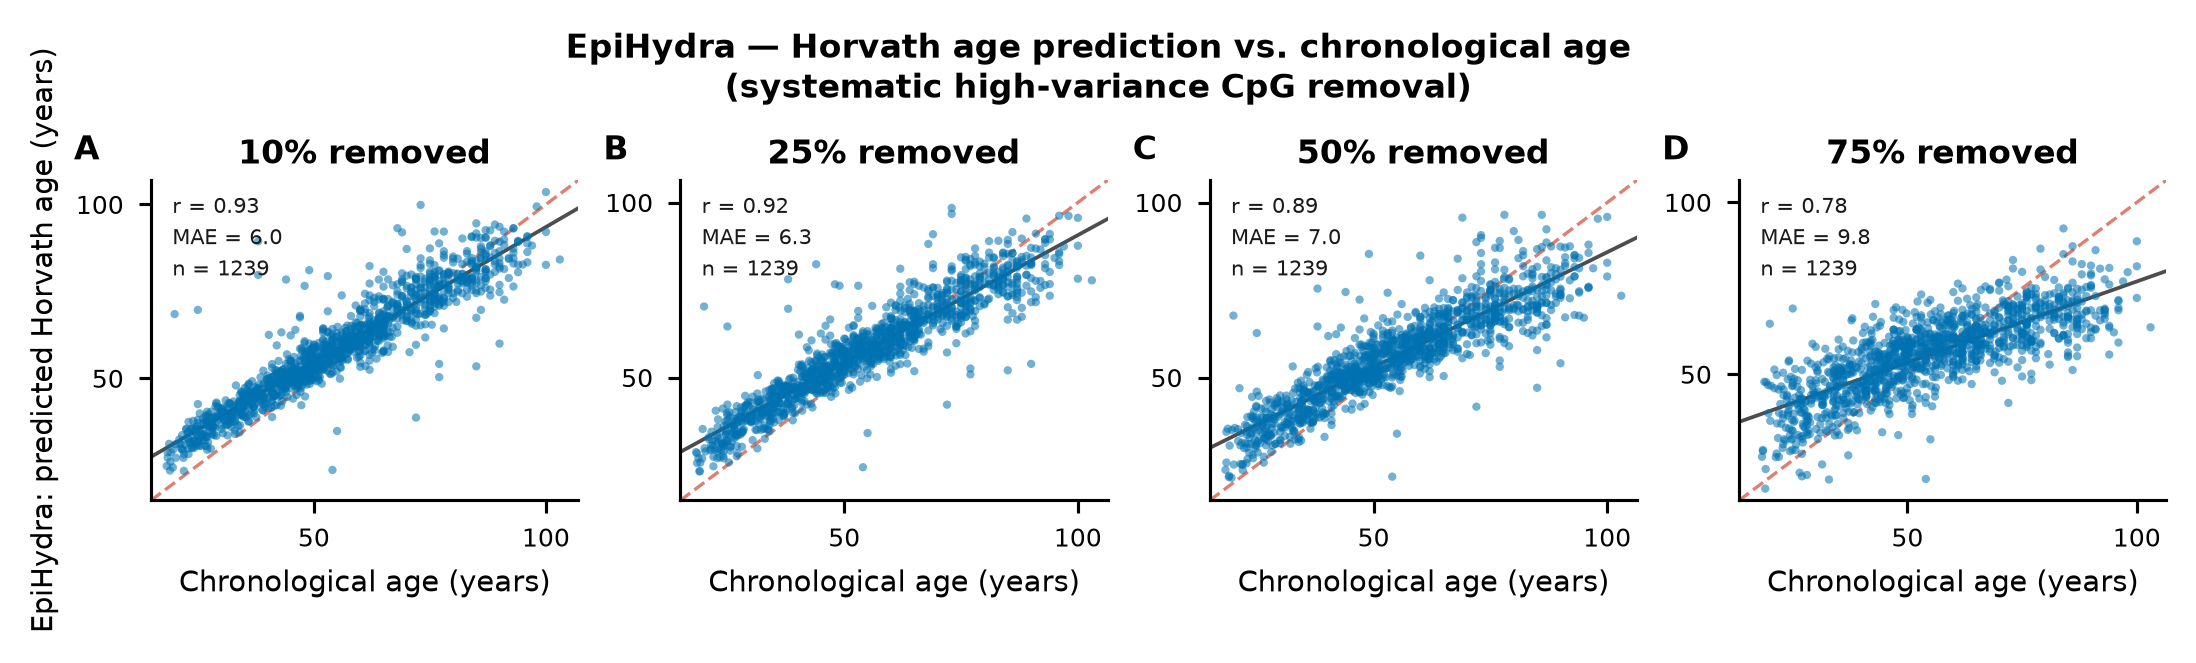

In [31]:
def plot_epihydra_scatter_row(all_preds, fracs=REMOVAL_FRACTIONS, save_stem=None):
    """
    Single row of scatter panels: EpiHydra Horvath pred vs. chron age
    at each of the four key removal fractions.
    NM double column (183 mm), 1 × 4 layout.
    """
    n = len(fracs)
    pw = (183 / n) * _MM
    ph = pw * 1.1

    with plt.rc_context(_NM_RC):
        fig, axes = plt.subplots(
            1, n,
            figsize=(n * pw, ph),
            constrained_layout=True,
        )
        if n == 1:
            axes = [axes]

        for i, (ax, frac) in enumerate(zip(axes, fracs)):
            sub = all_preds[
                (all_preds['model'] == 'EpiHydra') &
                (all_preds['frac']  == frac)
            ].dropna(subset=['pred', 'chron_age'])

            st = _scatter_panel_chron(
                ax, sub['pred'].values, sub['chron_age'].values,
                frac=frac, model='EpiHydra',
                panel_letter=_PANEL_LETTERS[i],
            )
            ax.set_title(f'{int(frac*100)}% removed', pad=4, fontweight='bold')
            ax.set_xlabel('Chronological age (years)')
            ax.set_ylabel('EpiHydra: predicted Horvath age (years)' if i == 0 else '')

        fig.suptitle(
            'EpiHydra — Horvath age prediction vs. chronological age\n'
            '(systematic high-variance CpG removal)',
            fontsize=8, fontweight='bold',
        )

    if save_stem:
        _save_fig(fig, save_stem)
    return fig, axes


fig_epi, axes_epi = plot_epihydra_scatter_row(
    all_preds,
    fracs=REMOVAL_FRACTIONS,
    save_stem='epihydra_horvath_vs_chron',
)
plt.show()

## 10 · Scatter panels: Horvath linear prediction vs. chronological age

Mirror of Section 9 for the linear Horvath clock — allows direct visual comparison of panel shape and spread with the EpiHydra counterparts above.

Saved → figures/ComparativeChronAgeModel/linear_horvath_vs_chron.svg
Saved → figures/ComparativeChronAgeModel/linear_horvath_vs_chron.pdf


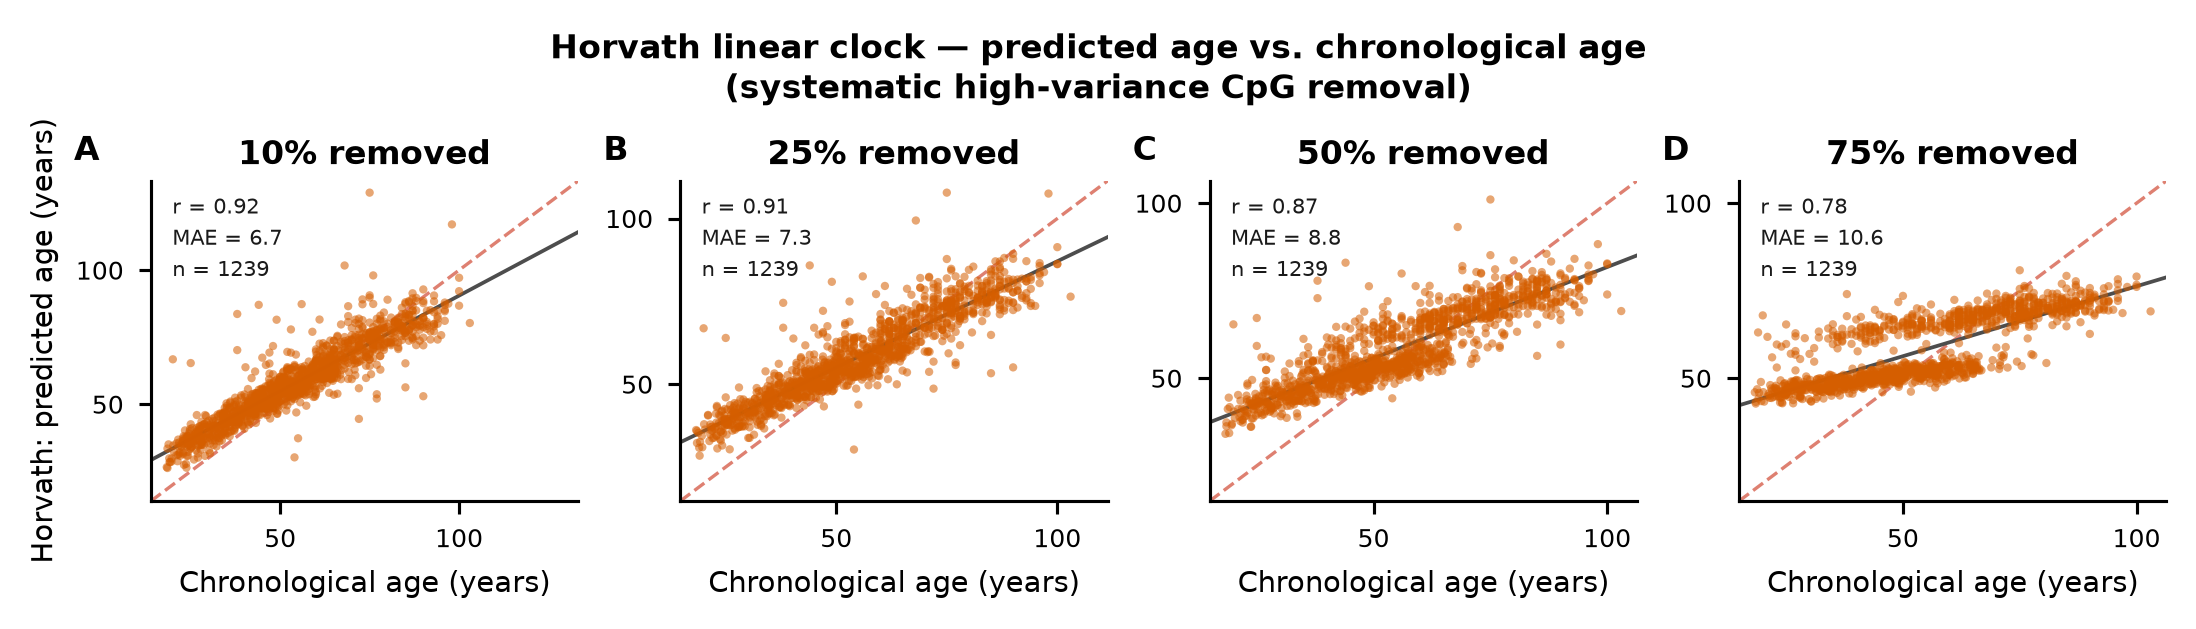

In [32]:
def plot_linear_scatter_row(all_preds, fracs=REMOVAL_FRACTIONS, save_stem=None):
    """Single row: Horvath linear pred vs. chron age at each removal fraction."""
    n = len(fracs)
    pw = (183 / n) * _MM
    ph = pw * 1.1

    with plt.rc_context(_NM_RC):
        fig, axes = plt.subplots(
            1, n,
            figsize=(n * pw, ph),
            constrained_layout=True,
        )
        if n == 1:
            axes = [axes]

        for i, (ax, frac) in enumerate(zip(axes, fracs)):
            sub = all_preds[
                (all_preds['model'] == 'Horvath (linear)') &
                (all_preds['frac']  == frac)
            ].dropna(subset=['pred', 'chron_age'])

            _scatter_panel_chron(
                ax, sub['pred'].values, sub['chron_age'].values,
                frac=frac, model='Horvath (linear)',
                panel_letter=_PANEL_LETTERS[i],
            )
            ax.set_title(f'{int(frac*100)}% removed', pad=4, fontweight='bold')
            ax.set_xlabel('Chronological age (years)')
            ax.set_ylabel('Horvath: predicted age (years)' if i == 0 else '')

        fig.suptitle(
            'Horvath linear clock — predicted age vs. chronological age\n'
            '(systematic high-variance CpG removal)',
            fontsize=8, fontweight='bold',
        )

    if save_stem:
        _save_fig(fig, save_stem)
    return fig, axes


fig_lin, axes_lin = plot_linear_scatter_row(
    all_preds,
    fracs=REMOVAL_FRACTIONS,
    save_stem='linear_horvath_vs_chron',
)
plt.show()

## 11 · MAE bar chart at key fractions

A compact summary figure: grouped bars per removal fraction, one bar per model, y = MAE vs. chronological age. Suitable as a main-text summary panel.

Saved → figures/ComparativeChronAgeModel/mae_bars_vs_chron.svg
Saved → figures/ComparativeChronAgeModel/mae_bars_vs_chron.pdf


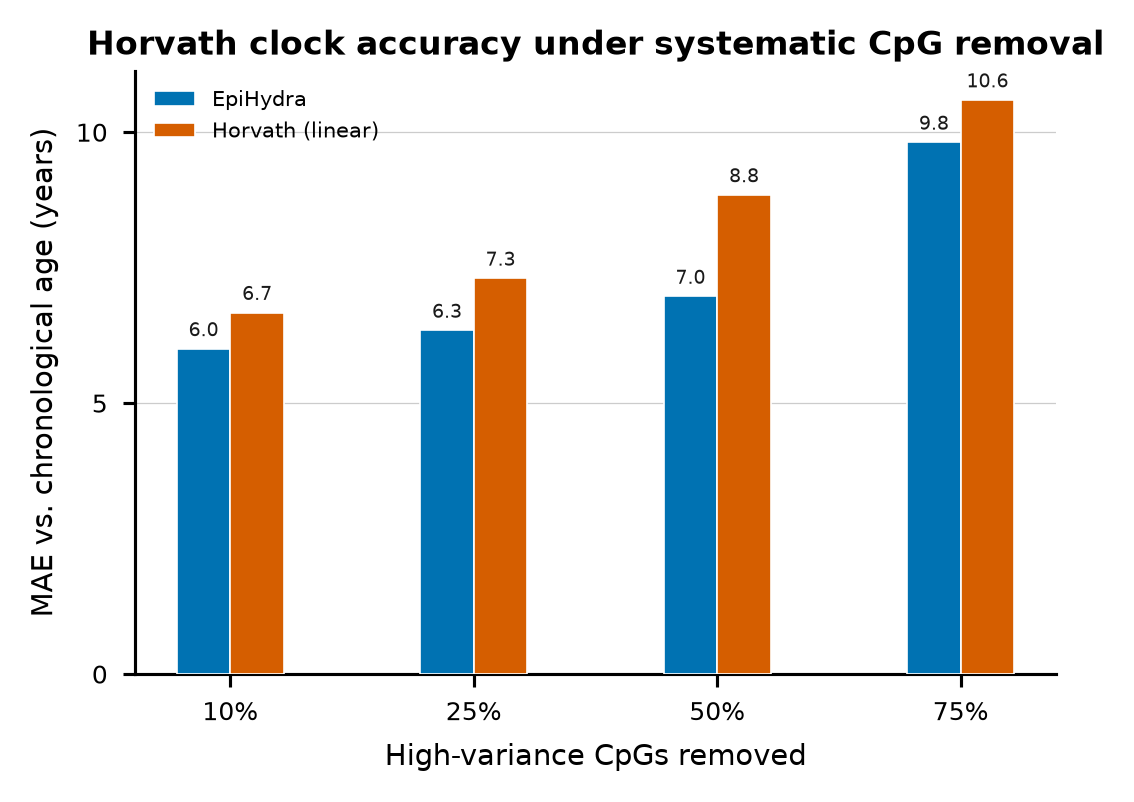

In [33]:
def plot_mae_bars(metrics_df, fracs=REMOVAL_FRACTIONS, save_stem=None):
    """
    Grouped bar chart: x = removal fraction, bars = models, y = MAE vs. chron age.
    Single NM column (89 mm).
    """
    sub  = metrics_df[metrics_df['frac'].isin(fracs)].copy()
    n_m  = len(MODEL_ORDER)
    n_f  = len(fracs)
    x    = np.arange(n_f)
    w    = 0.22   # bar width

    with plt.rc_context(_NM_RC):
        fig, ax = plt.subplots(figsize=(89 * _MM, 65 * _MM), constrained_layout=True)

        for i, model in enumerate(MODEL_ORDER):
            vals = [
                sub.loc[(sub['model'] == model) & (sub['frac'] == f), 'mae'].values[0]
                if len(sub.loc[(sub['model'] == model) & (sub['frac'] == f)]) else np.nan
                for f in fracs
            ]
            s = MODEL_STYLE[model]
            offset = (i - (n_m - 1) / 2) * w
            bars = ax.bar(
                x + offset, vals, width=w,
                color=s['color'], edgecolor='white',
                linewidth=0.4, label=model, zorder=3,
            )
            # Value labels on bars
            for bar, v in zip(bars, vals):
                if np.isfinite(v):
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + 0.15,
                        f'{v:.1f}',
                        ha='center', va='bottom', fontsize=4.5, color='#1a1a1a',
                    )

        ax.set_xticks(x)
        ax.set_xticklabels([f'{int(f*100)}%' for f in fracs])
        ax.set_xlabel('High-variance CpGs removed')
        ax.set_ylabel('MAE vs. chronological age (years)')
        ax.set_title(
            'Horvath clock accuracy under systematic CpG removal',
            pad=4, fontweight='bold',
        )
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, fontsize=5, loc='upper left')
        ax.grid(axis='y', lw=0.3, color='#CCCCCC', zorder=0)
        ax.set_axisbelow(True)

    if save_stem:
        _save_fig(fig, save_stem)
    return fig, ax


fig_bars, ax_bars = plot_mae_bars(
    metrics_df,
    fracs=REMOVAL_FRACTIONS,
    save_stem='mae_bars_vs_chron',
)
plt.show()

## 12 · Relative improvement of EpiHydra over Horvath linear

Δ MAE = MAE(EpiHydra) − MAE(Horvath linear), where both are scored against chronological age. A negative Δ means EpiHydra is closer to true age. The gap should widen at higher removal fractions if EpiHydra is more robust to missingness.

Saved → figures/ComparativeChronAgeModel/delta_mae_vs_linear.svg
Saved → figures/ComparativeChronAgeModel/delta_mae_vs_linear.pdf


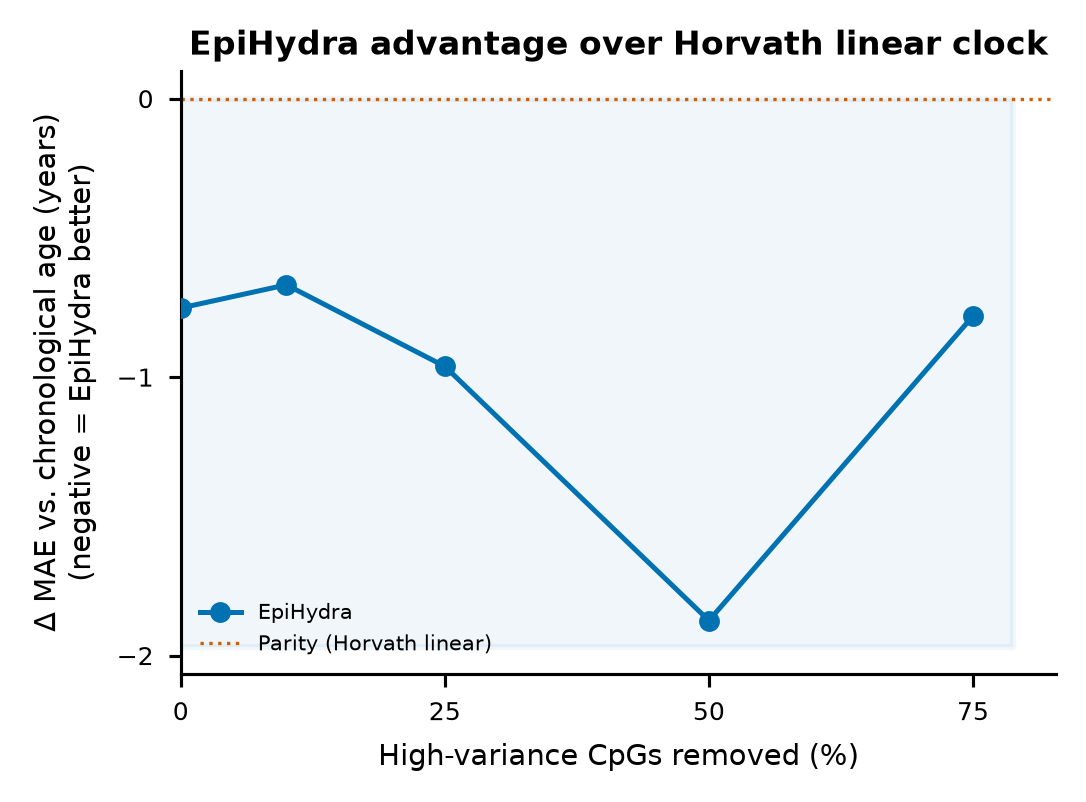

In [36]:
def plot_delta_mae(metrics_df, fracs=ALL_FRACTIONS, save_stem=None):
    """
    Δ MAE vs. Horvath linear for EpiHydra variants.
    Negative = EpiHydra better (lower MAE).
    Single NM column (89 mm).
    """
    lin_mae = metrics_df[metrics_df['model'] == 'Horvath (linear)'].set_index('frac')['mae']

    with plt.rc_context(_NM_RC):
        fig, ax = plt.subplots(figsize=(89 * _MM, 65 * _MM), constrained_layout=True)

        for model in ['EpiHydra']:
            sub  = metrics_df[metrics_df['model'] == model].set_index('frac')['mae']
            # Align fracs
            shared = sub.index.intersection(lin_mae.index)
            delta  = sub.loc[shared] - lin_mae.loc[shared]
            s = MODEL_STYLE[model]
            ax.plot(
                delta.index * 100, delta.values,
                color=s['color'], ls=s['ls'],
                lw=s['lw'], marker=s['marker'],
                markersize=4, zorder=s['zorder'],
                label=model,
            )

        ax.axhline(0, color='#D55E00', lw=0.8, ls=':', zorder=1,
                   label='Parity (Horvath linear)')
        ax.fill_between(
            ax.get_xlim(), ax.get_ylim()[0] if ax.get_ylim()[0] < 0 else -1, 0,
            color='#0072B2', alpha=0.06, zorder=0,
        )

        ax.set_xlabel('High-variance CpGs removed (%)')
        ax.set_ylabel('Δ MAE vs. chronological age (years)\n(negative = EpiHydra better)')
        ax.set_title(
            'EpiHydra advantage over Horvath linear clock',
            pad=4, fontweight='bold',
        )
        ax.set_xlim(left=0)
        ax.legend(handles=_legend_handles(['EpiHydra']) + [
            Line2D([0], [0], color='#D55E00', lw=0.8, ls=':', label='Parity (Horvath linear)')
        ], frameon=False, fontsize=5)

    if save_stem:
        _save_fig(fig, save_stem)
    return fig, ax


fig_delta, ax_delta = plot_delta_mae(
    metrics_df,
    fracs=ALL_FRACTIONS,
    save_stem='delta_mae_vs_linear',
)
plt.show()

## 13 · Quantitative summary table

In [37]:
def _highlight_best(s):
    """Green highlight on the minimum MAE per row (fraction)."""
    is_min = s == s.min()
    return ['background-color: #d4edda; font-weight: bold' if v else '' for v in is_min]


summary_table = metrics_df[metrics_df['frac'].isin(ALL_FRACTIONS)].copy()
summary_table['removal_%'] = (summary_table['frac'] * 100).astype(int)

# Wide format: index = (model, removal_%), columns = metrics
wide = summary_table.pivot_table(
    index=['removal_%', 'model'],
    values=['mae', 'pearson_r', 'r2', 'n'],
).round(3)
wide.to_csv(SAVE_DIR / 'summary_table_vs_chron.csv')
print('Summary table saved.')

# MAE pivot for quick reading
mae_pivot = summary_table.pivot_table(
    index='removal_%', columns='model', values='mae',
)[MODEL_ORDER].round(2)
mae_pivot.index.name = 'Removal (%)'

mae_pivot.style \
    .apply(_highlight_best, axis=1) \
    .set_caption(
        'MAE vs. chronological age (years) at each removal fraction '
        '— green = best model; Horvath is designed to predict chron age '
        'so this is the natural evaluation axis'
    )

Summary table saved.


model,EpiHydra,Horvath (linear)
Removal (%),,
0,5.570000,6.330000
10,6.000000,6.670000
25,6.340000,7.300000
50,6.970000,8.840000
75,9.810000,10.590000


## 14 · Export figure file manifest

In [ ]:
saved = sorted(SAVE_DIR.glob('*'))
print(f'{len(saved)} files in {SAVE_DIR}:\n')
for p in saved:
    size = p.stat().st_size / 1024
    print(f'  {p.name:<55}  {size:6.0f} kB')